### 1. Load Dataset dan Pembagian Data (70% Training, 30% Testing)

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# Load dataset breast cancer
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Membagi dataset: 70% training dan 30% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

# Standarisasi fitur (sangat penting khususnya untuk Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Jumlah Data Training: {X_train.shape[0]} sampel")
print(f"Jumlah Data Testing: {X_test.shape[0]} sampel")

Jumlah Data Training: 398 sampel
Jumlah Data Testing: 171 sampel


### 1.2 Pembagian Dataset dengan Proporsi 70% Training dan 30% Testing

In [30]:
# Pembagian dataset dengan proporsi 70:30 secara eksplisit
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

# Menampilkan proporsi hasil pembagian
total_samples = len(X)
train_size = len(X_train)
test_size = len(X_test)

print(f"Total data keseluruhan : {total_samples} sampel")
print(f"Data Training (70%)    : {train_size} sampel (Proporsi: {train_size/total_samples*100:.1f}%)")
print(f"Data Testing (30%)     : {test_size} sampel (Proporsi: {test_size/total_samples*100:.1f}%)")

Total data keseluruhan : 569 sampel
Data Training (70%)    : 398 sampel (Proporsi: 69.9%)
Data Testing (30%)     : 171 sampel (Proporsi: 30.1%)


### 1.1 Visualisasi Distribusi Kelas Target

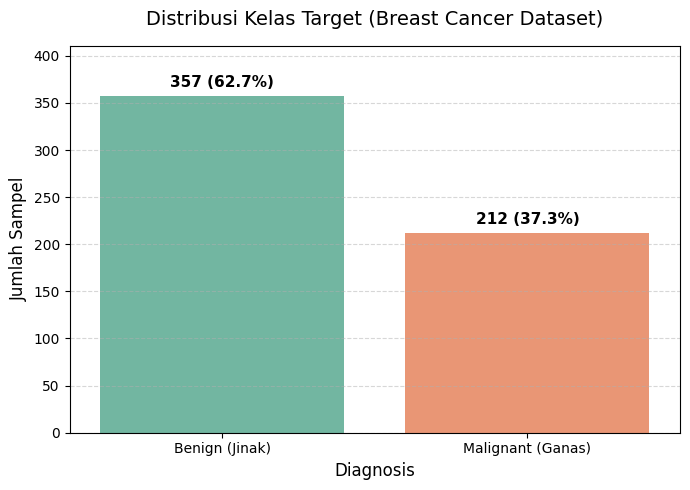

In [24]:
# Menghitung distribusi kelas
class_counts = pd.Series(y).map({0: 'Malignant (Ganas)', 1: 'Benign (Jinak)'}).value_counts()
percent = pd.Series(y).map({0: 'Malignant (Ganas)', 1: 'Benign (Jinak)'}).value_counts(normalize=True) * 100

# Membuat diagram batang
plt.figure(figsize=(7, 5))
ax = sns.barplot(x=class_counts.index, y=class_counts.values, palette='Set2', hue=class_counts.index, legend=False)

# Menambahkan label nilai dan persentase di atas batang
for i, p in enumerate(ax.patches):
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2., height + 10,
            f'{int(height)} ({percent.iloc[i]:.1f}%)',
            ha="center", fontsize=11, fontweight='bold')

plt.title('Distribusi Kelas Target (Breast Cancer Dataset)', fontsize=14, pad=15)
plt.xlabel('Diagnosis', fontsize=12)
plt.ylabel('Jumlah Sampel', fontsize=12)
plt.ylim(0, max(class_counts.values) * 1.15) # Memberikan ruang untuk label di atas bar
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 2. Implementasi & Evaluasi Logistic Regression

=== LOGISTIC REGRESSION REPORT ===
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171



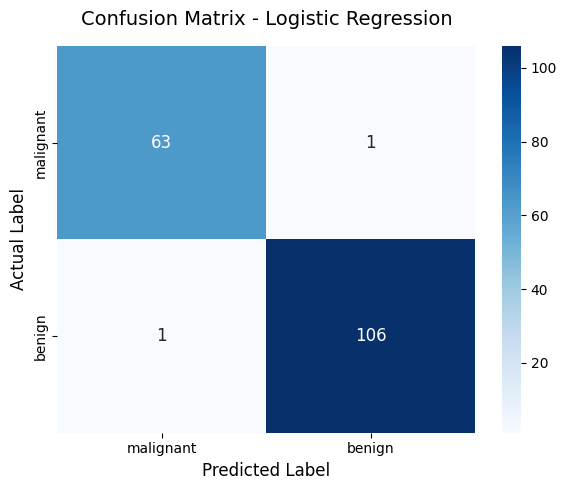

In [26]:
# Inisialisasi dan latih model
lr_model = LogisticRegression(random_state=42, max_iter=10000)
lr_model.fit(X_train_scaled, y_train)

# Prediksi
y_pred_lr = lr_model.predict(X_test_scaled)

# Evaluasi
print("=== LOGISTIC REGRESSION REPORT ===")
print(classification_report(y_test, y_pred_lr, target_names=data.target_names))

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues',
            xticklabels=data.target_names, yticklabels=data.target_names,
            annot_kws={'size': 12}, cbar=True)
plt.title('Confusion Matrix - Logistic Regression', fontsize=14, pad=15)
plt.ylabel('Actual Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plt.show()

### 3. Implementasi & Evaluasi Random Forest Classifier

=== RANDOM FOREST REPORT ===
              precision    recall  f1-score   support

   malignant       0.92      0.91      0.91        64
      benign       0.94      0.95      0.95       107

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



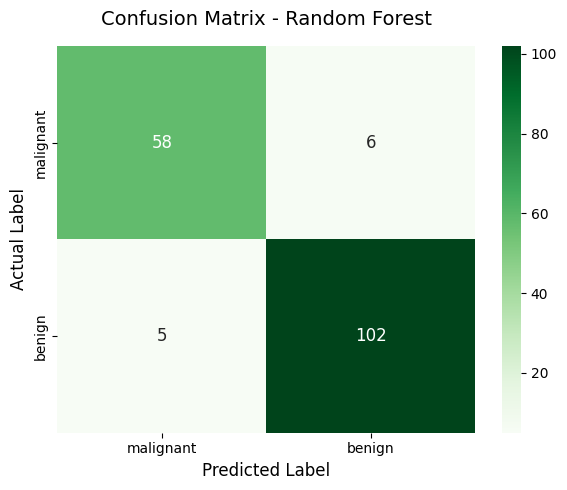

In [27]:
# Inisialisasi dan latih model
rf_model = RandomForestClassifier(random_state=42, n_estimators=100)
rf_model.fit(X_train, y_train)

# Prediksi
y_pred_rf = rf_model.predict(X_test)

# Evaluasi
print("=== RANDOM FOREST REPORT ===")
print(classification_report(y_test, y_pred_rf, target_names=data.target_names))

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Greens',
            xticklabels=data.target_names, yticklabels=data.target_names,
            annot_kws={'size': 12}, cbar=True)
plt.title('Confusion Matrix - Random Forest', fontsize=14, pad=15)
plt.ylabel('Actual Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plt.show()

### 4. Perbandingan Hasil dan Analisis

In [28]:
# Menyusun dataframe perbandingan performa
metrics_summary = {
    'Metric': ['Accuracy', 'Precision (Weighted)', 'Recall (Weighted)', 'F1-Score (Weighted)'],
    'Logistic Regression': [
        accuracy_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_lr, average='weighted'),
        recall_score(y_test, y_pred_lr, average='weighted'),
        f1_score(y_test, y_pred_lr, average='weighted')
    ],
    'Random Forest': [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf, average='weighted'),
        recall_score(y_test, y_pred_rf, average='weighted'),
        f1_score(y_test, y_pred_rf, average='weighted')
    ]
}

df_compare = pd.DataFrame(metrics_summary)
display(df_compare)

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.988304,0.935673
1,Precision (Weighted),0.988304,0.935533
2,Recall (Weighted),0.988304,0.935673
3,F1-Score (Weighted),0.988304,0.935569


### 5. Visualisasi Feature Importance (Random Forest)

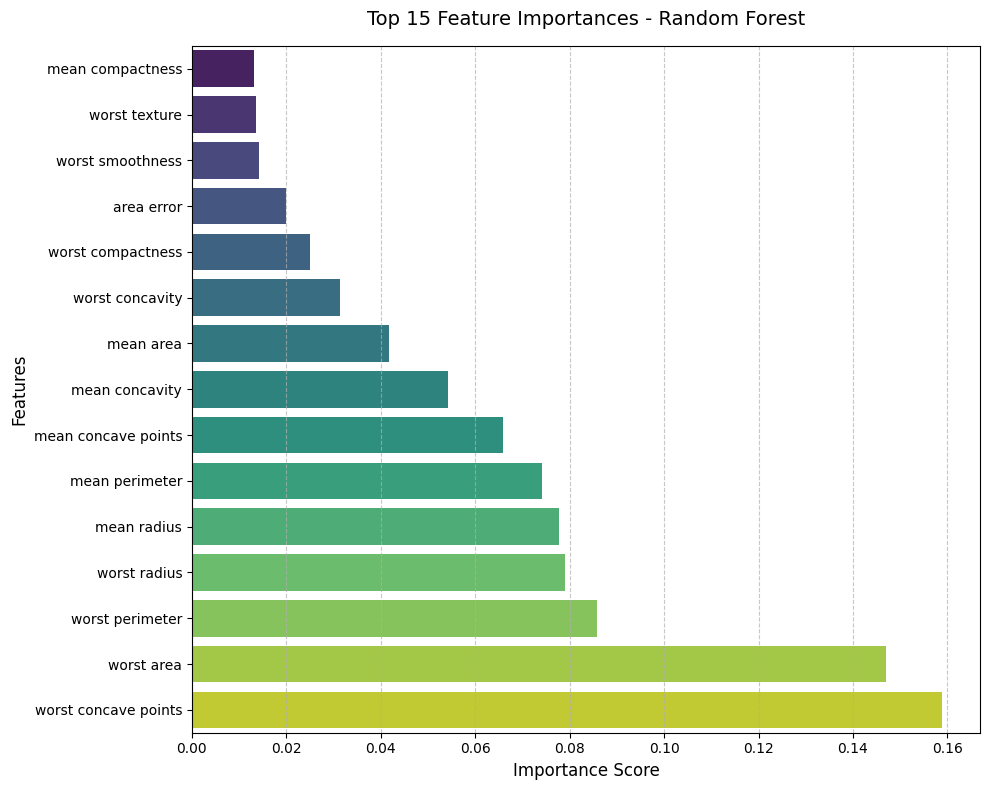

In [29]:
# Mengambil nilai feature importance dari model
importances = rf_model.feature_importances_
features = X.columns

# Membuat DataFrame untuk memudahkan sorting dan plotting
df_importance = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=True) # Ascending true agar plot barh terurut dari terbesar di atas

# Menampilkan 15 fitur paling berpengaruh dengan visualisasi yang rapi
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=df_importance.tail(15), palette='viridis', hue='Feature', legend=False)
plt.title('Top 15 Feature Importances - Random Forest', fontsize=14, pad=15)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 6. Tuning Hyperparameter Random Forest menggunakan GridSearchCV

In [22]:
from sklearn.model_selection import GridSearchCV

# Definisikan grid parameter yang akan diuji
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

# Inisialisasi model dasar
rf_base = RandomForestClassifier(random_state=42)

# Inisialisasi GridSearchCV dengan 5-fold cross-validation
grid_search = GridSearchCV(estimator=rf_base, param_grid=param_grid,
                           cv=5, n_jobs=-1, scoring='accuracy', verbose=1)

# Latih GridSearchCV pada data training asli
grid_search.fit(X_train, y_train)

# Menampilkan parameter terbaik yang ditemukan
print("=== Parameter Terbaik ===")
print(grid_search.best_params_)
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
=== Parameter Terbaik ===
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best Cross-Validation Accuracy: 0.9725


### 7. Evaluasi Model Random Forest yang Telah Di-tuning

In [23]:
# Gunakan model terbaik untuk memprediksi data test
best_rf_model = grid_search.best_estimator_
y_pred_tuned_rf = best_rf_model.predict(X_test)

# Evaluasi performa model yang baru
print("=== TUNED RANDOM FOREST REPORT ===")
print(classification_report(y_test, y_pred_tuned_rf, target_names=data.target_names))

# Bandingkan akurasi sebelum dan sesudah tuning
accuracy_before = accuracy_score(y_test, y_pred_rf)
accuracy_after = accuracy_score(y_test, y_pred_tuned_rf)
print(f"Akurasi Random Forest Sebelum Tuning : {accuracy_before:.4f}")
print(f"Akurasi Random Forest Setelah Tuning : {accuracy_after:.4f}")

=== TUNED RANDOM FOREST REPORT ===
              precision    recall  f1-score   support

   malignant       0.92      0.91      0.91        64
      benign       0.94      0.95      0.95       107

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171

Akurasi Random Forest Sebelum Tuning : 0.9357
Akurasi Random Forest Setelah Tuning : 0.9357


### 8. Mengapa Akurasi Saja Tidak Cukup dalam Klasifikasi Kanker?

Dalam klasifikasi medis, khususnya diagnosis penyakit kritis seperti kanker payudara, mengandalkan metrik **Akurasi (Accuracy)** saja bisa sangat menyesatkan dan berbahaya. Berikut adalah beberapa alasan utamanya:

#### 1. Masalah Ketidakseimbangan Kelas (*Imbalanced Data*)
* Jika sebuah dataset memiliki 95% sampel sehat (negatif) dan hanya 5% sampel kanker (positif), model naif yang memprediksi semua pasien sebagai "sehat" akan memiliki **Akurasi 95%**.
* Meskipun akurasinya sangat tinggi, model tersebut **gagal total** dalam mendeteksi satu pun pasien kanker. Ini membuktikan bahwa akurasi tinggi tidak menjamin model tersebut berguna secara klinis.

#### 2. Dampak Fatal dari *False Negative* (Tipe Error II)
* **False Negative (FN):** Pasien sebenarnya menderita kanker (ganas), tetapi model memprediksinya sebagai sehat (jinak).
* **Konsekuensi:** Pasien tidak akan menerima penanganan medis yang cepat dan tepat, sehingga sel kanker dapat menyebar lebih jauh dan mengancam keselamatan jiwa pasien.
* Oleh karena itu, kita membutuhkan metrik **Recall (Sensitivity)** yang tinggi. *Recall* mengukur seberapa baik model dalam menemukan seluruh pasien yang benar-benar sakit kanker.
  $$\text{Recall} = \frac{\text{True Positive (TP)}}{\text{True Positive (TP)} + \text{False Negative (FN)}}$$

#### 3. Dampak dari *False Positive* (Tipe Error I)
* **False Positive (FP):** Pasien sebenarnya sehat (jinak), tetapi model memprediksinya sebagai kanker (ganas).
* **Konsekuensi:** Pasien akan mengalami stres psikologis yang berat dan mungkin harus menjalani prosedur medis lanjutan yang invasif dan mahal (seperti biopsi tambahan) yang sebenarnya tidak diperlukan.
* Untuk meminimalkan kesalahan ini, kita memantau metrik **Precision**. *Precision* memastikan bahwa pasien yang diprediksi positif kanker benar-benar sakit kanker.
  $$\text{Precision} = \frac{\text{True Positive (TP)}}{\text{True Positive (TP)} + \text{False Positive (FP)}}$$

#### 4. Keseimbangan melalui *F1-Score*
* **F1-Score** adalah rata-rata harmonis antara *Precision* dan *Recall*:
  $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$
* Metrik ini memberikan gambaran performa model yang seimbang dan objektif, terutama saat kita ingin memastikan nilai *Recall* yang sangat tinggi (meminimalisir FN) tanpa mengorbankan nilai *Precision* terlalu banyak (meminimalisir FP).

**Kesimpulan Klinis:**
Dalam klasifikasi kanker, prioritas utama adalah **memaksimalkan Recall** untuk memastikan tidak ada pasien kanker yang lolos dari diagnosis (menekan *False Negative* hingga mendekati nol), sambil tetap menjaga **F1-Score** yang optimal.